In [1]:
# IMPORT NEEDED MODULES
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler, MinMaxScaler

In [7]:
# IMPORT THE DATASET
df= pd.read_csv("Wholesale customers data.csv")
df.head()

,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
0,2,3,12669,9656,7561,214,2674,1338
1,2,3,7057,9810,9568,1762,3293,1776
2,2,3,6353,8808,7684,2405,3516,7844
3,1,3,13265,1196,4221,6404,507,1788
4,2,3,22615,5410,7198,3915,1777,5185


In [4]:
# GETTING THE INDEPENDENT VARIABLES
x_var = df.drop(['Channel','Region'], axis='columns')
x_var.head()

,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
0,12669,9656,7561,214,2674,1338
1,7057,9810,9568,1762,3293,1776
2,6353,8808,7684,2405,3516,7844
3,13265,1196,4221,6404,507,1788
4,22615,5410,7198,3915,1777,5185


In [5]:
# scale the dataset to ensure high magnitude dors not affect the
# clustering algorithm
scaler = StandardScaler()

In [6]:
# Scale the x_var, that's the independent variables
x_scaled = scaler.fit_transform(x_var)

In [8]:
x_scaled

array([[ 0.05293319,  0.52356777, -0.04111489, -0.58936716, -0.04356873,
        -0.06633906],
       [-0.39130197,  0.54445767,  0.17031835, -0.27013618,  0.08640684,
         0.08915105],
       [-0.44702926,  0.40853771, -0.0281571 , -0.13753572,  0.13323164,
         2.24329255],
       ...,
       [ 0.20032554,  1.31467078,  2.34838631, -0.54337975,  2.51121768,
         0.12145607],
       [-0.13538389, -0.51753572, -0.60251388, -0.41944059, -0.56977032,
         0.21304614],
       [-0.72930698, -0.5559243 , -0.57322717, -0.62009417, -0.50488752,
        -0.52286938]], shape=(440, 6))

In [13]:
#import os
#os.environ["OMP_NUM_THREADS"] ="2"
import warnings
warnings.filterwarnings('ignore', category=UserWarning)

In [14]:
# calc the inertia or sse( sum of squared errors) for a
# range of k values

sse = []
k_range = range(1,10)
for k in k_range:
    km = KMeans(n_clusters=k,random_state=42,n_init='auto')
    km.fit(x_scaled)
    sse.append(km.inertia_)

In [15]:
sse

[2640.0,
 2266.9552665832452,
 1644.0598512347563,
 1326.674608213553,
 1070.2551995135614,
 989.3326418885057,
 856.7070228388116,
 791.8280762163155,
 710.1943394067519]

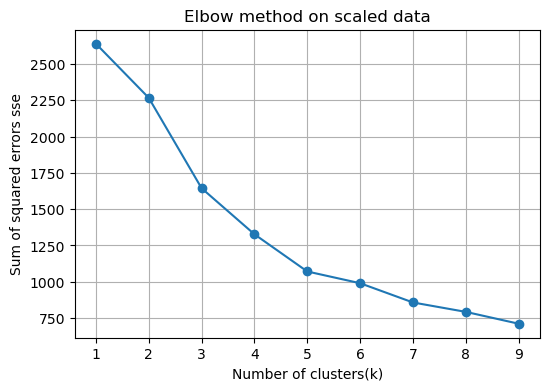

In [16]:
# plot the elbow curve
plt.figure(figsize=(6,4))
plt.plot(k_range,sse, marker='o')
plt.title('Elbow method on scaled data')
plt.xlabel('Number of clusters(k)')
plt.ylabel('Sum of squared errors sse')
plt.grid(True)
plt.show()

In [17]:
# Reading the elbow joint is ambiguous,so we use Silhouette score
from sklearn.metrics import silhouette_score

In [18]:
# Test k values from 2 to 8
range_k = range(2,8)
silhouette_scores = []
for k in range_k:
    # INITIALIZE AND FIT KMEANS
    mk = KMeans(n_clusters=k,random_state=42,n_init=10)
    cluster_labels = mk.fit_predict(x_scaled)
    # CALCULATE THE SILHOUETTE SCORE
    score = silhouette_score(x_scaled,cluster_labels)
    silhouette_scores.append(score)
    print(f"For K = {k}, Silhoette Score = {score:.4f}")
    

For K = 2, Silhoette Score = 0.5472
For K = 3, Silhoette Score = 0.5483
For K = 4, Silhoette Score = 0.3485
For K = 5, Silhoette Score = 0.3690
For K = 6, Silhoette Score = 0.3782
For K = 7, Silhoette Score = 0.3343


In [19]:
# NOW USE K=3, since k=3 returned the highest Silhouette score(0.5483)
kmeans_final = KMeans(n_clusters=3,random_state=42,n_init='auto')
kmeans_final.fit(x_scaled)

,n_clusters,3
,init,'k-means++'
,n_init,'auto'
,max_iter,300
,tol,0.0001
,verbose,0
,random_state,42
,copy_x,True
,algorithm,'lloyd'


In [20]:
df.columns

Index(['Channel', 'Region', 'Fresh', 'Milk', 'Grocery', 'Frozen',
       'Detergents_Paper', 'Delicassen'],
      dtype='object')

In [52]:
#df.drop('Clusters',axis='columns',inplace=True)

In [21]:
# get the labels into the originak dataset
df['Clusters'] = kmeans_final.labels_

In [22]:
df.head()

,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen,Clusters
0,2,3,12669,9656,7561,214,2674,1338,0
1,2,3,7057,9810,9568,1762,3293,1776,0
2,2,3,6353,8808,7684,2405,3516,7844,0
3,1,3,13265,1196,4221,6404,507,1788,0
4,2,3,22615,5410,7198,3915,1777,5185,1


In [30]:
df['Clusters'].value_counts()

Clusters
0    350
1     53
2     37
Name: count, dtype: int64

In [34]:
# Group by clusters and get the mean for each spending feature
cluster_summary = df.groupby('Clusters')[['Fresh','Milk','Grocery','Frozen','Detergents_Paper','Delicassen']].mean()
cluster_summary['Customer_count'] = df['Clusters'].value_counts()
print(cluster_summary)

                 Fresh          Milk       Grocery       Frozen  \
Clusters                                                          
0          8935.500000   4228.528571   5848.034286  2167.231429   
1         34540.113208   5860.358491   6122.622642  9841.735849   
2          8704.864865  20534.405405  30466.243243  1932.621622   

          Detergents_Paper   Delicassen  Customer_count  
Clusters                                                 
0              1913.605714  1102.120000             350  
1               981.471698  3664.245283              53  
2             14758.837838  2459.351351              37  


In [43]:
#cluster_summary.drop('Customer_count',axis='columns',inplace=True)

In [44]:
cluster_summary

,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
Clusters,,,,,,
0,8935.500000,4228.528571,5848.034286,2167.231429,1913.605714,1102.120000
1,34540.113208,5860.358491,6122.622642,9841.735849,981.471698,3664.245283
2,8704.864865,20534.405405,30466.243243,1932.621622,14758.837838,2459.351351


In [45]:
# HOW DO CLUSTERS MAP TO THE ORIGINAL BUSINESS PLAN?
print(pd.crosstab(df['Channel'],df['Clusters']))

Clusters    0   1   2
Channel              
1         251  47   0
2          99   6  37


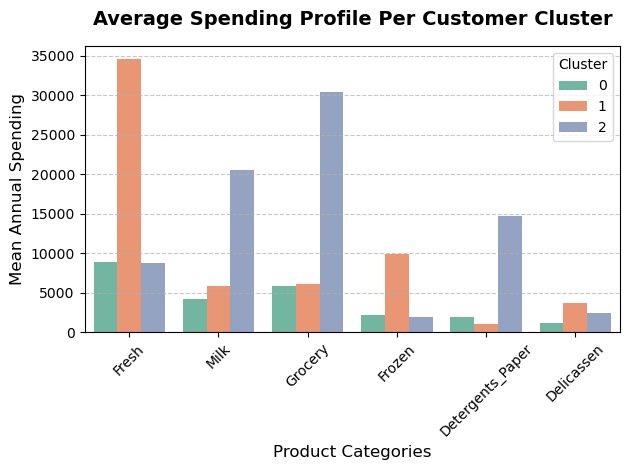

In [47]:
# Bar chart showing cluster spending profile
summary_melt = cluster_summary.reset_index().melt(
    id_vars='Clusters',
    var_name='Spending_Category',
    value_name='Mean_Spending'
)

sns.barplot(
    data= summary_melt,
    x='Spending_Category',
    y='Mean_Spending',
    hue='Clusters',
    palette='Set2'
)

plt.title('Average Spending Profile Per Customer Cluster', fontsize=14, fontweight='bold',pad=15)
plt.xlabel('Product Categories', fontsize=12)
plt.ylabel('Mean Annual Spending', fontsize=12)
plt.xticks(rotation=45)
plt.legend(title='Cluster', loc='upper right')
plt.grid(axis='y', linestyle='--',alpha=0.7)

plt.tight_layout()
plt.show()


In [ ]:
# CLUSTERS 1 HAVE THE HIGHEST SPENDING IN FRESH, FROZEN AND DELICACY.
# IT SUGGESTS THAT THE CUSTOMERS ARE THE HOTELS, RESTAURANTS, EATERY, ETC
# CLUSTERS 0 ARE THE EVERY DAY STANDARD FOOD SERVICE
# CLUSTERS 2 ARE THE RETAIL SUPERMARKETS/ GLOCERS. IT SHOWS IN THE ITEMS THEY DOMINATED
# IN THEIR SPENDING - MILK, GLOCERY AND DETERGENTS_PAPER